# FishSim dolphin–gannet pilot: evidence, model and reproduction

**Run All** verifies 48 completed feeding encounters and three separate timing checks, reconstructs 48 sealed horizons from the new eight-school cohort, regenerates the four current figures, and exports twelve tables. The saved outputs were generated by these cells. Default execution takes **zero native simulation steps**.

This snapshot preserves the earlier 24 encounters and adds a separate **eight-school cohort with 24 D/G/DG encounters**. Each new encounter has sealed 36T primary and 72T secondary records. These are 48 encounters in total, not 72 independent samples. Earlier two-school repetitions are not pooled with the eight new schools. Original inventories and seals remain intact; the finer-timestep study is pending and excluded.

**Primary finding:** the new cohort gives a mean dolphin change of+1 capture per school, with a 97.5% marginal interval from−2.375 to+5. Gannets gain+5.125 captures, interval 2.75 to 7. Dolphin benefit remains unresolved; a general mutual advantage is not established.

Start with [README.md](README.md) for local Jupyter installation on Windows, macOS or Linux. Optional execution of the actual frozen model appears at the end and is disabled by default.


In [1]:
from pathlib import Path
import json
import sys

NOTEBOOK_DIR = Path.cwd().resolve()
if not (NOTEBOOK_DIR / "notebook_support.py").is_file():
    raise RuntimeError("Open Jupyter in the folder containing this notebook and notebook_support.py.")
sys.path.insert(0, str(NOTEBOOK_DIR))
import notebook_support_v3 as study
print(json.dumps(study.verify_inputs(), indent=2))


{
  "status": "passed",
  "snapshot": "2026-11-09_0231",
  "feeding_encounters": 48,
  "earlier_encounters_preserved": 24,
  "new_encounters": 24,
  "new_sealed_horizons": 48,
  "new_independent_schools": 8,
  "protected_files": 3595,
  "supporting_engineering_checks": 3,
  "engineering_pooled": false,
  "native_steps": 0
}


## What the model actually assumes

Each dolphin applies local pressure while moving around a tracked prey patch. It may launch one physically feasible strike after **2T of continuous proximity to any currently observed fish within radius 4.5**. It then handles a capture or recovers from a miss and repeats. The proximity clock is not a test that the pod has compacted the school. A fragmented school or isolated reachable fish remains eligible.

`nearest` ranks feasible targets by distance. `exposed` first prefers fewer observed neighbours within radius 2, then interception geometry and distance; this is a preference, not a sparse-fish-only rule. The same policy is used in D and DG. Dolphins do **not** explicitly wait for a bird dive or post-dive scatter in this experiment.

Gannets observe all underwater fish within their depth limit. DBSCAN-style density groups use radius 2 and at least four neighbours including self. A group is selected with probability proportional to accessible population, then a locally dense fish is targeted. Population weighting is distinct from density weighting.

The capture probability **0.7 applies at a resolved physical oral contact**, not per launch or dive. These runs were not calibrated to field dive-success observations; the field categories should not be interpreted as repeated attempts on the same fish. Space and time units are uncalibrated; 36T is not 36 seconds. There is no energy budget, evolutionary learning, numerical convergence claim or demonstration of long-term cooperation. The matched controls below permit a narrower test of joint feeding gains in these particular encounters.


In [2]:
study.print_table(study.actual_parameter_table())


parameter                                    | value  
---------------------------------------------+--------
Initial fish                                 | 160    
Dolphins                                     | 12     
Gannets in DG                                | 3      
Native timestep T                            | 0.00125
Earlier encounter duration T                 | 36     
Continuous proximity requirement T           | 2      
Fish proximity radius                        | 4.5    
Exposed neighbor radius                      | 2      
Dolphin speed                                | 6      
Dolphin sensing radius                       | 25     
Maximum strike duration T                    | 6      
Successful handling T                        | 2      
Miss recovery T                              | 0.75   
Gannet detection depth                       | 12     
Gannet sensing radius (global approximation) | 1e+09  
Conditional oral-contact success             | 0.7    
New-cohort

## The code that implements target choice

These cells print definitions directly from the frozen model files. They do not execute the controller or replace it with pseudocode. The shared launch guard checks reachability and turning feasibility before a fish enters the ranked candidate list.


In [3]:
controller = "research/exposed_replication_2026-11-08/controllers.py"
print(study.source_excerpt(controller, "SimpleHerdStrikePlanner._candidates"))


    def _candidates(self, state, observation, config):
        x = np.asarray(observation.positions, float).reshape(-1, 3)
        v = np.asarray(observation.velocities, float).reshape(-1, 3)
        if not len(x):
            return [], np.empty(0, dtype=int)
        counts = np.asarray(cKDTree(x).query_ball_point(x, NEIGHBOUR_RADIUS,
                            return_length=True))-1
        distances = np.linalg.norm(x-np.asarray(state.position), axis=1)
        rows = []
        for i in np.flatnonzero(distances <= self.parameters.launch_radius):
            eligible, guard = shared_launch_guard(state, x[i], v[i], config,
                                                   self.parameters.launch_radius)
            if eligible:
                rows.append((int(i), guard))
        if self.policy == 'nearest':
            rows.sort(key=lambda r: (float(distances[r[0]]), observation.prey_ids[r[0]]))
        else:
            rows.sort(key=lambda r: (int(counts[r[0]]),
                r

The cycle implementation below shows the actual pressure reset, 2T threshold, one-strike launch and recovery handling. `memory.maintenance_started` stores the pressure clock. Only committed transitions are subsequently logged.


In [4]:
print(study.source_excerpt(controller, "SimpleHerdStrikePlanner._resolve"))


    def _resolve(self, memory, state, observation, config, events, phase_events, seen_at):
        diagnostic = dict(policy=VERSION, cycle_policy=self.policy, actor_id=state.actor_id,
            time=state.time, observation_time=seen_at, observed_count=len(observation.prey_ids),
            launch_allowed=False, launch_reason='pressure_not_ready', current_patch=False,
            actual_proximity=False, pressure_started=memory.maintenance_started,
            pressure_elapsed=0., target_id=state.target_id,
            selected_neighbor_count=None, feasible_min_neighbor_count=None, feasible_count=0)
        if state.mode == 'attack':
            diagnostic['launch_reason'] = 'active_bout'
            return memory, state, None, diagnostic
        if state.mode == 'recovery':
            if memory.phase != 'recovery':
                memory = self._recovery_memory(memory, state.mode_since)
            if state.time < state.ready_at-EPSILON:
                diagnostic['launch_reason'] = 

The actual gannet target-selection function uses its own recorded random stream. Its cluster draw and final target can be replayed from the sealed bird-event logs.


In [5]:
gannet = "research/exposed_replication_2026-11-08/gannet.py"
print(study.source_excerpt(gannet, "select_dense_target"))


def select_dense_target(state, observation, config, *, rng=None):
    """Sample a dense cluster by accessible fish count, then aim at its density peak.

    The planner supplies its private target RNG. A fixed default seed makes this
    standalone helper reproducible for diagnostics. Accessibility is a coarse
    current-position travel/depth check, never a guarantee of mouth contact.
    Full observation is provided by the builder's global sensing radius; the
    inherited underwater detection-depth restriction is retained.
    """
    rng = np.random.default_rng(0) if rng is None else rng
    local = observe(state, observation.positions, observation.velocities,
                    np.asarray(observation.prey_ids, dtype=np.int64), config)
    x = np.asarray(local.positions, dtype=float).reshape(-1, 3)
    ids = np.asarray(local.prey_ids, dtype=np.int64)
    patches, labels = dense_clusters(x)
    depth_limit = config.max_dive_depth - config.speed / config.turn_rate - config.ascent_ma

## Earlier exploratory evidence: kept separate

Captures below are counted from successful physical oral events, checked for unique prey IDs, and reconciled with each completed summary. These earlier 24 cases are 36T, with 28,800 steps each. New-cohort results are reconstructed separately below from their sealed horizon prefixes. The existing paper tables are independently checked against these reconstructed counts. The depth treatments translate initial fish positions vertically while retaining their original habitat preference; depth remains free to change.


In [6]:
rows = study.case_rows()
development = study.paired_rows(rows, "development")
replication = study.paired_rows(rows, "replication")
study.print_table(rows, ["study", "school", "capture_seed", "policy", "presence", "dolphin_captures", "gannet_captures", "dolphin_launches", "captures_per_launch"])


study        | school   | capture_seed | policy   | presence | dolphin_captures | gannet_captures | dolphin_launches | captures_per_launch
-------------+----------+--------------+----------+----------+------------------+-----------------+------------------+--------------------
development  | 39061001 | 61001        | exposed  | D        | 22               | 0               | 56               | 0.3929             
development  | 39061001 | 61001        | exposed  | DG       | 22               | 9               | 54               | 0.4074             
development  | 39061001 | 61001        | nearest  | D        | 26               | 0               | 52               | 0.5                
development  | 39061001 | 61001        | nearest  | DG       | 28               | 6               | 52               | 0.5385             
development  | 39061002 | 61001        | exposed  | D        | 19               | 0               | 46               | 0.413              
development  | 39061002 | 6

Development comparisons selected the exposed policy for fresh follow-up. They remain a separate exploratory set.


In [7]:
study.print_table(development, ["school", "policy", "D", "DG", "difference", "change_percent"])


school   | policy  | D  | DG | difference | change_percent
---------+---------+----+----+------------+---------------
39061001 | exposed | 22 | 22 | 0          | 0             
39061001 | nearest | 26 | 28 | 2          | 7.692         
39061002 | exposed | 19 | 26 | 7          | 36.84         
39061002 | nearest | 29 | 25 | -4         | -13.79        


The fresh comparisons preserve each school and capture stream. The following school means average only the two stochastic repetitions belonging to that school. No confidence interval or significance test is justified by two independent fresh schools.


In [8]:
study.print_table(replication, ["school", "capture_seed", "D", "DG", "difference", "change_percent"])
study.print_table(study.school_means(replication))
total_D = sum(row["D"] for row in replication)
total_DG = sum(row["DG"] for row in replication)
print(f"Fresh descriptive totals: {total_D} → {total_DG}; change {100*(total_DG-total_D)/total_D:.2f}%.")


school   | capture_seed | D  | DG | difference | change_percent
---------+--------------+----+----+------------+---------------
39063501 | 61001        | 23 | 24 | 1          | 4.348         
39063501 | 61002        | 20 | 24 | 4          | 20            
39063502 | 61001        | 22 | 23 | 1          | 4.545         
39063502 | 61002        | 22 | 30 | 8          | 36.36         
school   | repeated_streams | mean_D | mean_DG | mean_difference | positive_repetitions
---------+------------------+--------+---------+-----------------+---------------------
39063501 | 2                | 21.5   | 24      | 2.5             | 2                   
39063502 | 2                | 22     | 26.5    | 4.5             | 2                   
Fresh descriptive totals: 87 → 101; change 16.09%.


## Matching gannet controls and initial-depth results

The new G-only controls use the same bird states and private streams as the mixed runs. Only the unshifted G controls enter the joint-benefit comparison; depth treatments are not pooled into it. Initial fish depth is a transient intervention, not a maintained constraint.


In [9]:
joint = study.reciprocity_rows(rows)
depth = study.depth_rows(rows)
study.print_table(joint)
study.print_table(study.reciprocity_school_means(joint))
study.print_table(study.feeding_rate_summary(joint))
print("Both species gain in", sum(row["both_gain"] for row in joint), "of", len(joint), "repetitions, representing two independent schools.")


school   | capture_seed | D  | DG_D | D_difference | G  | DG_G | G_difference | D_rate_difference | G_rate_difference | both_gain
---------+--------------+----+------+--------------+----+------+--------------+-------------------+-------------------+----------
39063501 | 61001        | 23 | 24   | 1            | 8  | 7    | -1           | 0.002315          | -0.009259         | False    
39063501 | 61002        | 20 | 24   | 4            | 10 | 11   | 1            | 0.009259          | 0.009259          | True     
39063502 | 61001        | 22 | 23   | 1            | 6  | 5    | -1           | 0.002315          | -0.009259         | False    
39063502 | 61002        | 22 | 30   | 8            | 2  | 9    | 7            | 0.01852           | 0.06481           | True     
school   | repetitions | D_mean_difference | G_mean_difference | joint_positive_repetitions
---------+-------------+-------------------+-------------------+---------------------------
39063501 | 2           | 2.5        

Gannet captures change by −1, +1, −1 and +7 across the matched repetitions. Pooled totals rise from 26 to 32, but the gain is concentrated in one repetition; the two school-average changes are zero and +3. A same-policy dolphin gain also does not establish an advantage over the strongest tested independent alternative: development exposed DG produced 48 captures versus 55 for nearest D-only. That benchmark has not been evaluated on the fresh schools.


In [10]:
study.print_table(depth)


school   | treatment | capture_seed | G_captures | G_launches | G_contacts | captures_per_gannet_per_T | initial_mean_depth | initial_accessible_fraction | final_accessible_fraction
---------+-----------+--------------+------------+------------+------------+---------------------------+--------------------+-----------------------------+--------------------------
39063501 | baseline  | 61001        | 8          | 19         | 11         | 0.07407                   | 5.556              | 1                           | 0.9605                   
39063501 | depth8    | 61001        | 5          | 18         | 8          | 0.0463                    | 8                  | 0.4437                      | 0.1161                   
39063501 | depth11   | 61001        | 9          | 19         | 12         | 0.08333                   | 11                 | 0                           | 0.702                    
39063502 | baseline  | 61001        | 6          | 17         | 7          | 0.05556      

Initial mean depths 5.56/5.58, 8 and 11 produced G-only catches 8/6, 5/5 and 9/6 respectively. There is no monotonic decline. Fish initially outside the reference target-depth envelope can move into reach; the figure below shows changing accessibility throughout the encounter.



## Eight independent new schools: primary 36T, secondary 72T

One matched D/G/DG triplet represents each new school. Each horizon is reconstructed from its separately sealed event prefix. The 72T record continues the same encounter; it is not an additional independent observation. Complete depletion would freeze later food counts while ending physical effort at depletion; none occurred here.


In [11]:
new_horizons = study.horizon_rows()
new_pairs = study.longer_pairs(new_horizons)
study.print_table(new_pairs)


school   | horizon_T | D_alone | D_with_gannets | D_difference | G_alone | G_with_dolphins | G_difference | joint_positive | D_rate_difference | G_rate_difference
---------+-----------+---------+----------------+--------------+---------+-----------------+--------------+----------------+-------------------+------------------
39064501 | 36        | 24      | 22             | -2           | 2       | 9               | 7            | False          | -0.00463          | 0.06481          
39064502 | 36        | 17      | 20             | 3            | 3       | 7               | 4            | True           | 0.006944          | 0.03704          
39064503 | 36        | 22      | 21             | -1           | 3       | 11              | 8            | False          | -0.002315         | 0.07407          
39064504 | 36        | 20      | 18             | -2           | 6       | 11              | 5            | False          | -0.00463          | 0.0463           
39064505 | 36        |

The frozen primary analysis uses 10,000 draws of entire paired school vectors with shared resampling indices for both species. Two 97.5% marginal percentile intervals target approximate 95% familywise coverage, with unstable coverage/tails possible at n=8. No historical cases enter these statistics.


In [12]:
stats = study.primary_statistics(new_pairs)
study.print_table(stats)
primary = [r for r in new_pairs if r["horizon_T"] == 36.]
secondary = [r for r in new_pairs if r["horizon_T"] == 72.]
print("Primary 36T joint positive:", sum(r["joint_positive"] for r in primary), "of8 schools.")
print("Secondary 72T joint positive:", sum(r["joint_positive"] for r in secondary), "of8; descriptive, same trajectories.")
study.print_table(study.secondary_increments(new_pairs))


species | independent_schools | horizon_T | mean_capture_difference | marginal_97_5_lower | marginal_97_5_upper | bootstrap_draws | analysis_seed
--------+---------------------+-----------+-------------------------+---------------------+---------------------+-----------------+--------------
D       | 8                   | 36        | 1                       | -2.375              | 5                   | 10000           | 88491009     
G       | 8                   | 36        | 5.125                   | 2.75                | 7                   | 10000           | 88491009     
Primary 36T joint positive: 3 of8 schools.
Secondary 72T joint positive: 5 of8; descriptive, same trajectories.
school   | interval_T | D_alone | D_mixed | G_alone | G_mixed
---------+------------+---------+---------+---------+--------
39064501 | 36–72      | 20      | 30      | 4       | 6      
39064502 | 36–72      | 15      | 23      | 7       | 13     
39064503 | 36–72      | 24      | 22      | 11      | 6 

At 36T, dolphin captures total 168 alone and 176 mixed; gannet captures total 35 alone and 76 mixed. At 72T the totals are 352→380 for dolphins and 85→149 for gannets. The dolphin primary interval spans negative and positive effects, leaving its benefit unresolved. The 72T comparison is secondary and cannot replace the primary horizon because its effect is larger.

## Rebuild all four current paper figures

This executes the preserved paper figure source against the bundled sealed data. Figures are saved as PDF and PNG with source-hash receipts under `outputs/eight_school_figures/`. These match the eight-school report snapshot. Figure 3 shows the eight new schools; Figure 4 retains the earlier two-school controls and initial-depth pilot. Earlier source/reference sets remain intact. The finer-timestep follow-up is excluded.


In [13]:
figure_folder = study.reproduce_figures()


fig1_model
fig2_development
fig3_replication: eight independent schools,36Tprimary/72Tsecondary
fig4_mechanism


Figure 1. Model rules and an actual recorded dolphin–gannet encounter snapshot. The trajectories and capture locations come from sealed data.


Figure written: outputs/eight_school_figures/fig1_model.png


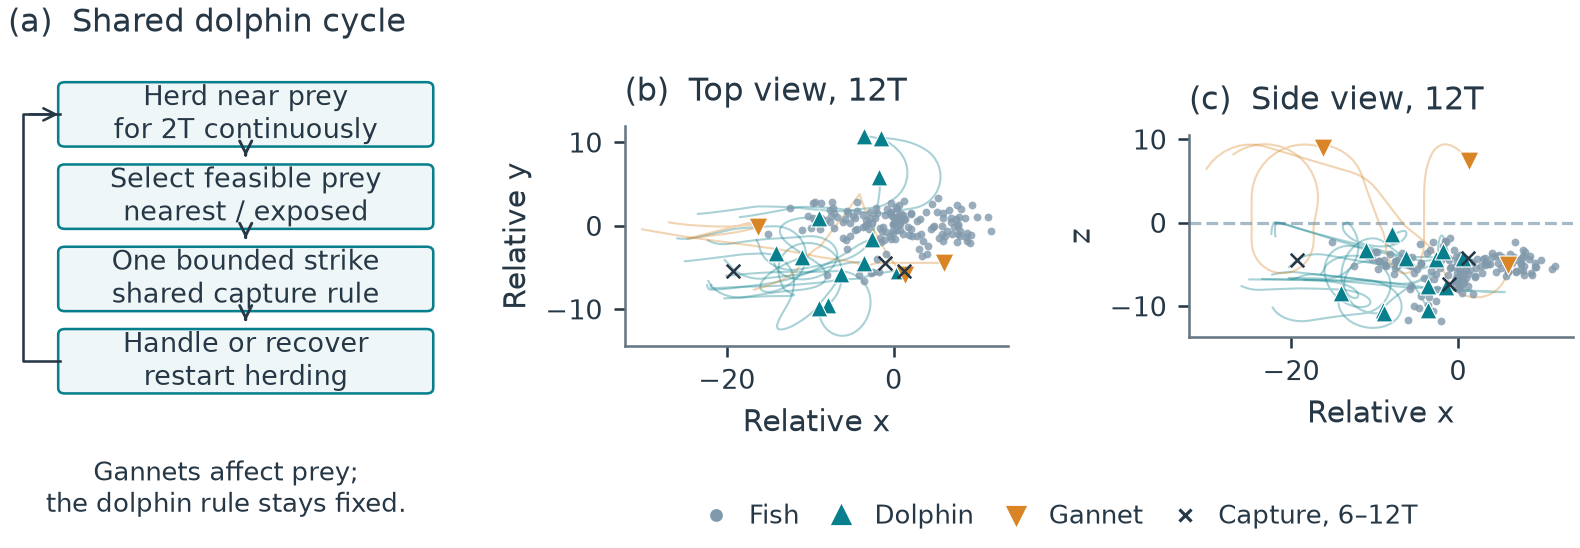

In [14]:
study.show_figure("fig1_model")


Figure 2. Development comparison: nearest and exposed policies across two starting schools. The exposed policy was selected using these exploratory results.


Figure written: outputs/eight_school_figures/fig2_development.png


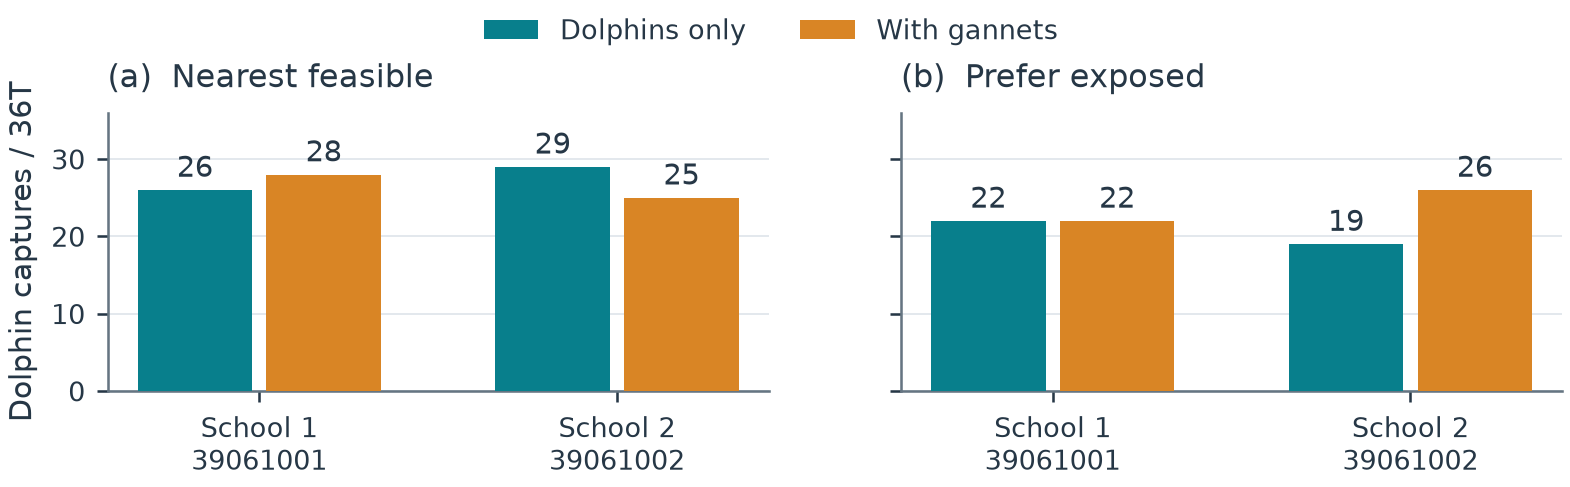

In [15]:
study.show_figure("fig2_development")


Figure 3. Eight-school partner effects at primary 36T and secondary 72T. The primary dolphin interval crosses zero; the gannet interval is positive. Earlier two-school results are excluded.


Figure written: outputs/eight_school_figures/fig3_replication.png


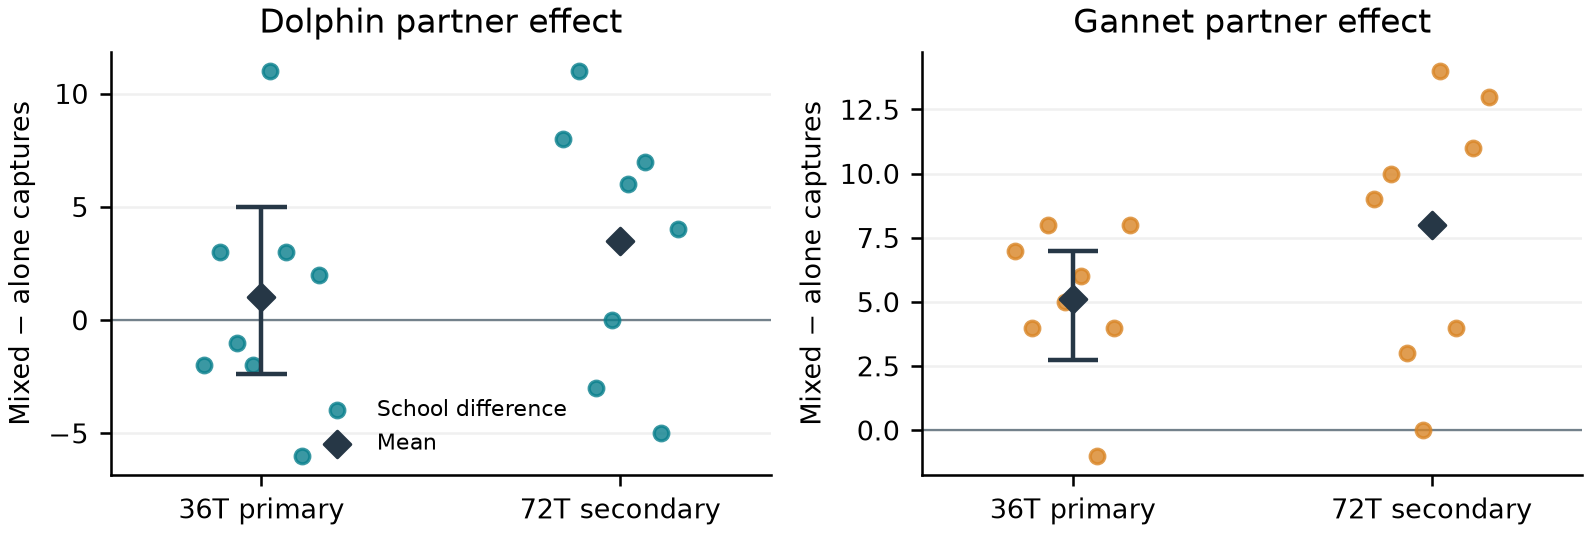

In [16]:
study.show_figure("fig3_replication")


Figure 4. Paired dolphin/gannet gains, G-only feeding across initial depths and realised accessibility. Both species gain in two repetitions; initial depth does not remain fixed.


Figure written: outputs/eight_school_figures/fig4_mechanism.png


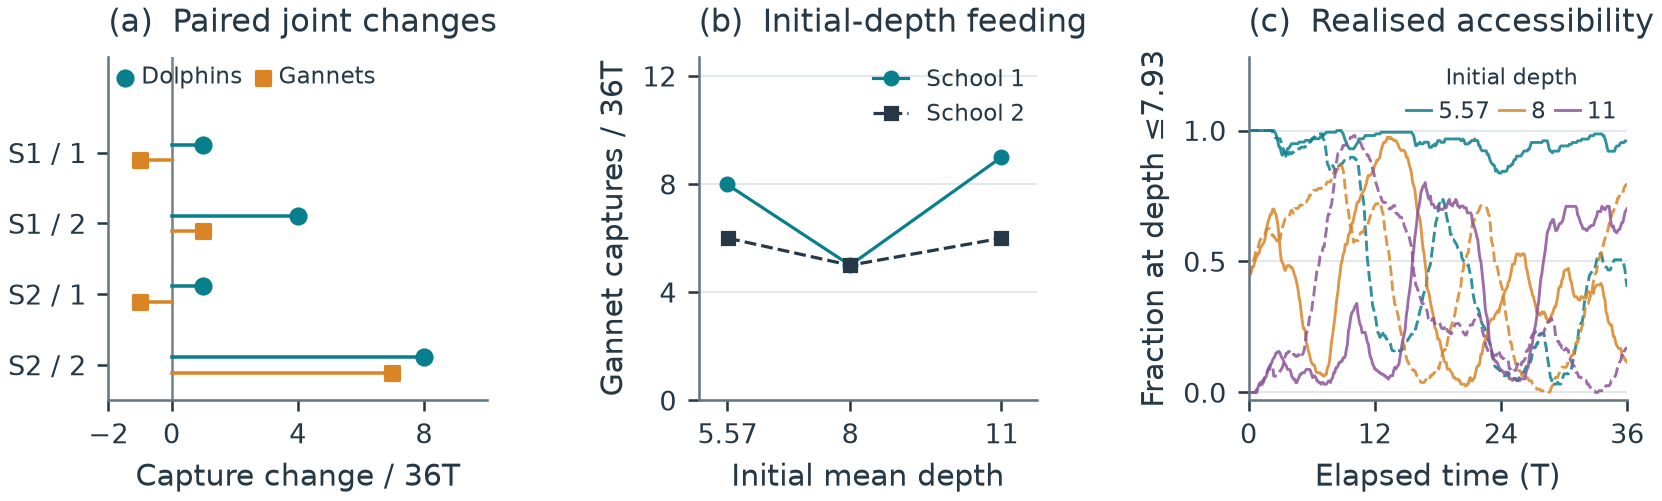

In [17]:
study.show_figure("fig4_mechanism")


In [18]:
study.export_tables(rows, development, replication, joint, depth, new_horizons, new_pairs, stats)


8 tables exported to outputs/current_tables
Four new-cohort tables exported; earlier eight tables remain in outputs/current_tables.


## Supporting timing checks: separate from the feeding comparisons

The [supporting timing evidence](supporting_evidence/timing/README.md) contains three sealed engineering checks: a disabled 4T replay, an enabled 8T feasibility run with no delay, and a post-hoc 36T demonstration with one partial 0.07624T hold and zero requested 1T releases. The selected demonstration had unchanged catches. These checks are verified separately and are not counted as new feeding replicates or pooled into the tables above. The full chronology, protocol amendments, case events, source closure and independent audits are bundled there. They do not establish a timing advantage.


## Optional: run the actual frozen model locally

This final section is **off by default**. The static report below imports no native code. Read [NATIVE_SETUP.md](NATIVE_SETUP.md) before switching it on. The supplied binary requires CPython 3.12 on Linux x 86-64 with glibc ≥2.43 and compatible C++/OpenMP libraries. The analysis above works independently of this requirement. Source and the real CMake recipe are included; another-platform rebuild is not validated and is intentionally rejected by the historical binary pin.

`QUICK_RUN=True` runs 0.5T D and 0.5T DG sequentially using actual prepared fish checkpoints and the actual coupled simulator. This is an integration check, **too short for the 2T cycle**, and supplies no feeding-benefit evidence. Set `QUICK_RUN=False` for a 36T matched pair. `FULL_REPLICATION=True` requests all eight 36T fresh-replication cases. New results are saved separately; the bundled evidence remains unchanged.


In [19]:
print(json.dumps(study.native_environment(), indent=2))


{
  "python": "3.12.13",
  "system": "Linux",
  "machine": "x86_64",
  "libc": "glibc 2.43",
  "eligible_for_native_import_check": true,
  "native_loaded": false,
  "native_steps": 0,
  "binary_sha256": "eb8654a520304cc429aced67c7e3706db8d2ef1449c5e1327a682a479b10a558",
  "note": "An explicit optional run also checks the actual native import and dependent libraries. Analysis and figures do not need this binary."
}


In [20]:
RUN_MODEL = False
QUICK_RUN = True
FULL_REPLICATION = False
SCHOOL_SEED = 39063501       # or 39063502
CAPTURE_SEED = 61001        # or 61002
WORKERS = 1                # up to 4 for the full eight-case replication

if RUN_MODEL:
    import subprocess
    from datetime import datetime
    output = NOTEBOOK_DIR / "outputs" / "model_runs" / datetime.now().strftime("%Y%m%d_%H%M%S")
    command = [sys.executable, str(NOTEBOOK_DIR / "run_model.py"),
               "--quick" if QUICK_RUN else "--full", "--school", str(SCHOOL_SEED),
               "--capture-seed", str(CAPTURE_SEED), "--workers", str(WORKERS), "--output", str(output)]
    if FULL_REPLICATION:
        if QUICK_RUN:
            raise ValueError("Full replication requires QUICK_RUN=False.")
        command.append("--all-replication")
    subprocess.run(command, check=True, cwd=NOTEBOOK_DIR)
    study.print_table(study.new_run_table(output))
else:
    print("Optional simulation not executed. Default analysis used zero native steps.")


Optional simulation not executed. Default analysis used zero native steps.
